In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, FuncFormatter, NullFormatter

# Per-example error files saved by the two evaluation notebooks
ERROR_FILES = {
    'FNO': 'fno_errors_all_buckets.npz',
    'CNN': 'store/cnn_errors_all_buckets.npz',
}
BUCKETS      = ['smooth', 'medium', 'rough']
RESOLUTIONS  = [128, 256, 512]
MODEL_COLORS = {'FNO': 'C0', 'CNN': 'C4'}
MODELS       = list(ERROR_FILES)

In [2]:
errors = {m: {b: {} for b in BUCKETS} for m in MODELS}
identity = {b: {} for b in BUCKETS}

for m, path in ERROR_FILES.items():
    with np.load(path) as f:
        for b in BUCKETS:
            for res in RESOLUTIONS:
                errors[m][b][res] = f[f'err_{b}_{res}']
                id_err = f[f'id_{b}_{res}']
                # Both models should have been scored on the same bucket files
                if res not in identity[b]:
                    identity[b][res] = id_err
                elif id_err.shape != identity[b][res].shape or not np.allclose(id_err, identity[b][res], rtol=1e-4):
                    print(f"WARNING: identity errors for {b} @ {res} differ between files; "
                          f"the models may not have been evaluated on the same data")
    print(f"Loaded {path}")

for b in BUCKETS:
    print(f"  {b:<7}: {len(identity[b][RESOLUTIONS[0]])} examples per resolution")

Loaded fno_errors_all_buckets.npz
Loaded store/cnn_errors_all_buckets.npz
  smooth : 20 examples per resolution
  medium : 20 examples per resolution
  rough  : 20 examples per resolution


In [4]:
def means(m, b):
    return [errors[m][b][res].mean() for res in RESOLUTIONS]

def identity_means(b):
    return [identity[b][res].mean() for res in RESOLUTIONS]

def growth(m, b):
    """Mean error at 256 and 512 relative to 128."""
    e = means(m, b)
    return [e[1] / e[0], e[2] / e[0]]

In [5]:
for b in BUCKETS:
    print(f"==================== {b.upper()} BUCKET ====================")
    header = f"{'Res':>4} |"
    for m in MODELS:
        header += f" {m + ' mean':>9} {m + ' median':>11} {'vs id':>7} |"
    header += f" {'Identity':>9}"
    print(header)
    print('-' * len(header))

    for res in RESOLUTIONS:
        id_mean = identity[b][res].mean()
        row = f"{res:>4} |"
        for m in MODELS:
            e = errors[m][b][res]
            row += f" {e.mean():>9.6f} {np.median(e):>11.6f} {id_mean / e.mean():>6.2f}x |"
        row += f" {id_mean:>9.6f}"
        print(row)

    print()
    for m in MODELS:
        g = growth(m, b)
        print(f"  {m} error growth:  128->256 {g[0]:5.2f}x    128->512 {g[1]:5.2f}x")
    print()

==================== SMOOTH BUCKET ====================
 Res |  FNO mean  FNO median   vs id |  CNN mean  CNN median   vs id |  Identity
--------------------------------------------------------------------------------
 128 |  0.000431    0.000338   9.82x |  0.000224    0.000175  18.89x |  0.004232
 256 |  0.000564    0.000484   7.50x |  0.002181    0.002289   1.94x |  0.004231
 512 |  0.000612    0.000499   6.92x |  0.003219    0.003327   1.31x |  0.004231

  FNO error growth:  128->256  1.31x    128->512  1.42x
  CNN error growth:  128->256  9.73x    128->512 14.36x

==================== MEDIUM BUCKET ====================
 Res |  FNO mean  FNO median   vs id |  CNN mean  CNN median   vs id |  Identity
--------------------------------------------------------------------------------
 128 |  0.001109    0.000686  17.28x |  0.000695    0.000561  27.55x |  0.019154
 256 |  0.001469    0.001069  13.04x |  0.010291    0.008578   1.86x |  0.019153
 512 |  0.001578    0.001200  12.14x |  0.014

In [6]:
def readable_log_axis(ax, values):
    """Log axis labelled at 1, 2, 5 x 10^k, with headroom for the legend."""
    ax.set_yscale('log')
    ax.set_ylim(min(values) * 0.7, max(values) * 2.2)
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:g}'))
    ax.yaxis.set_minor_formatter(NullFormatter())

In [9]:
def plot_model_buckets(m, output_path):
    """One row per bucket: model vs identity (left) and error growth vs 128 (right)."""
    fig, axes = plt.subplots(len(BUCKETS), 2, figsize=(12, 4 * len(BUCKETS)), sharey='col')
    x = np.arange(len(RESOLUTIONS))
    w = 0.35
    all_errors, all_growth = [], []

    for row, b in enumerate(BUCKETS):
        name = b.capitalize()
        model_means, id_means, g = means(m, b), identity_means(b), growth(m, b)
        all_errors += model_means + id_means
        all_growth += g

        ax = axes[row, 0]
        ax.bar(x - w / 2, model_means, w, label=m, color=MODEL_COLORS[m])
        ax.bar(x + w / 2, id_means, w, label='Identity', color='C1')
        ax.set_xticks(x)
        ax.set_xticklabels([str(res) for res in RESOLUTIONS])
        ax.set_xlabel('Resolution')
        ax.set_ylabel('Mean relative L² error')
        ax.set_yscale('log')
        ax.set_title(f'{name}: {m} vs identity baseline')
        ax.legend(loc='upper left', ncol=2)
        ax.grid(True, alpha=0.3)

        ax = axes[row, 1]
        ax.bar(['128→256', '128→512'], g, color=['C2', 'C3'])
        ax.axhline(1.0, color='gray', linestyle='--', linewidth=1)
        ax.set_ylabel('Growth ratio')
        ax.set_title(f'{name}: {m} error growth relative to 128')
        for i, value in enumerate(g):
            ax.text(i, value, f'{value:.2f}×', ha='center', va='bottom')
        ax.grid(True, alpha=0.3)

    readable_log_axis(axes[0, 0], all_errors)
    axes[0, 1].set_ylim(0, max(all_growth) * 1.15)

    plt.tight_layout()
    plt.savefig(output_path, dpi=150)
    plt.show()
    print(f"Saved {output_path}")

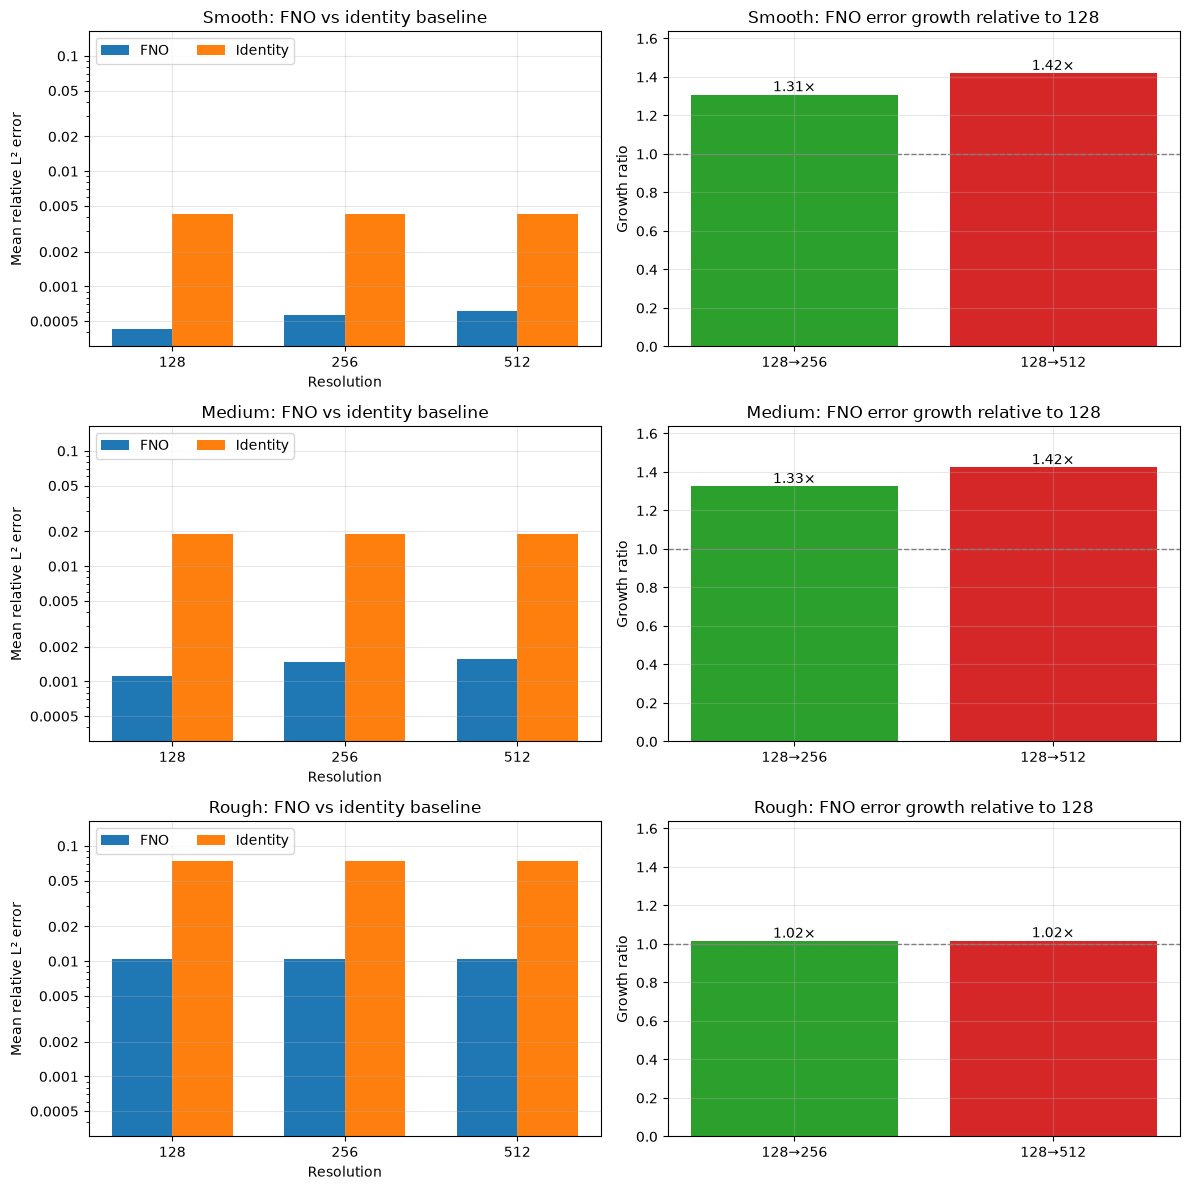

Saved fno_eval_buckets.png


In [10]:
plot_model_buckets('FNO', 'fno_eval_buckets.png')

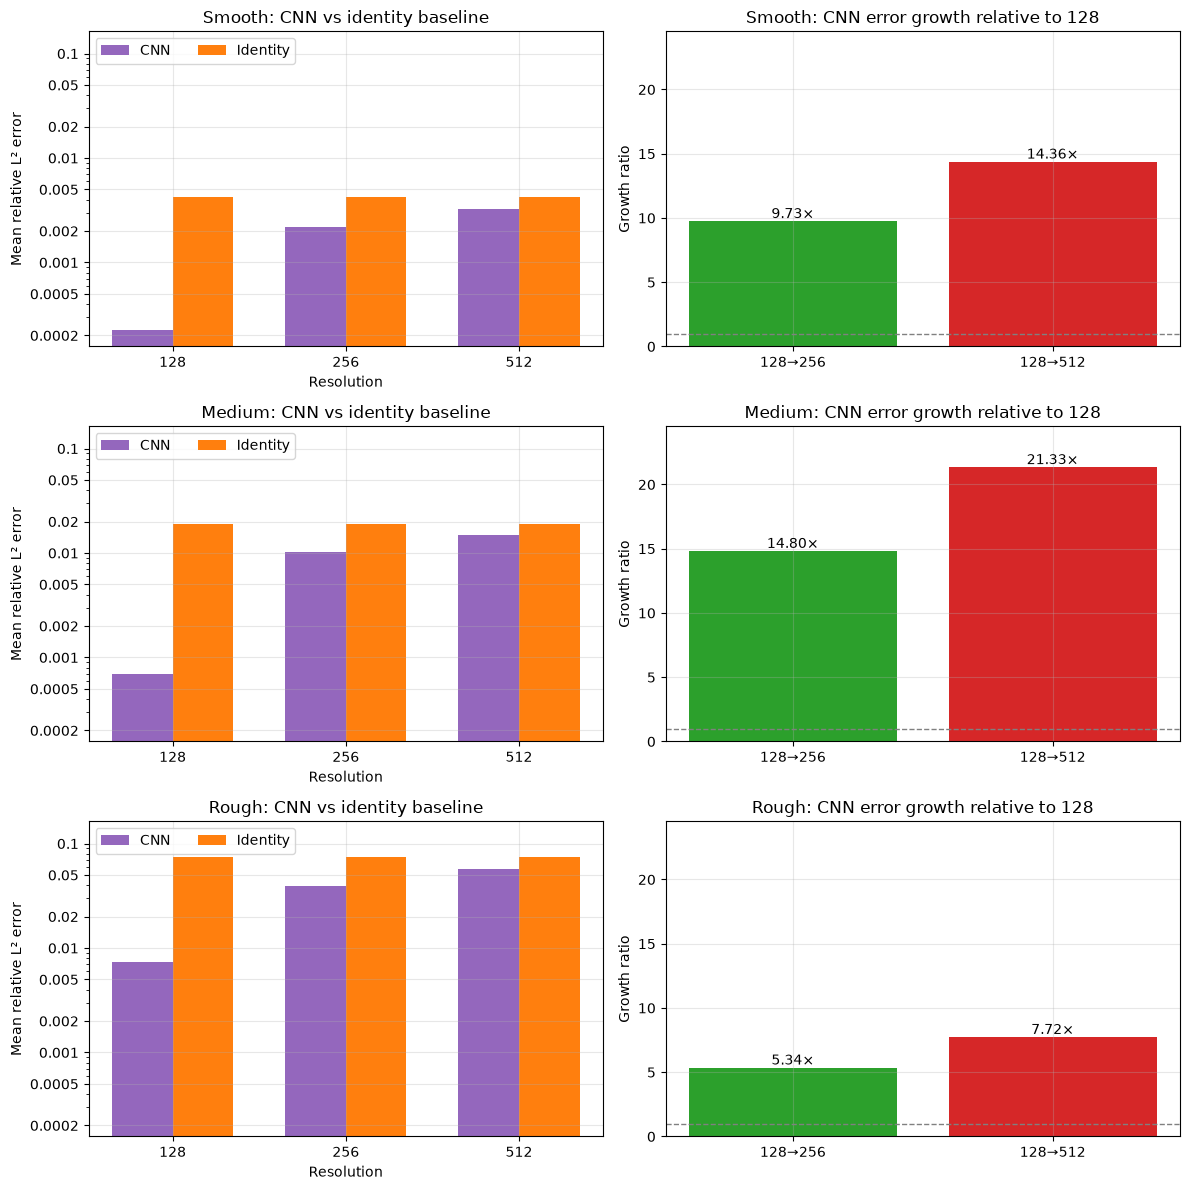

Saved cnn_eval_buckets.png


In [11]:
plot_model_buckets('CNN', 'cnn_eval_buckets.png')

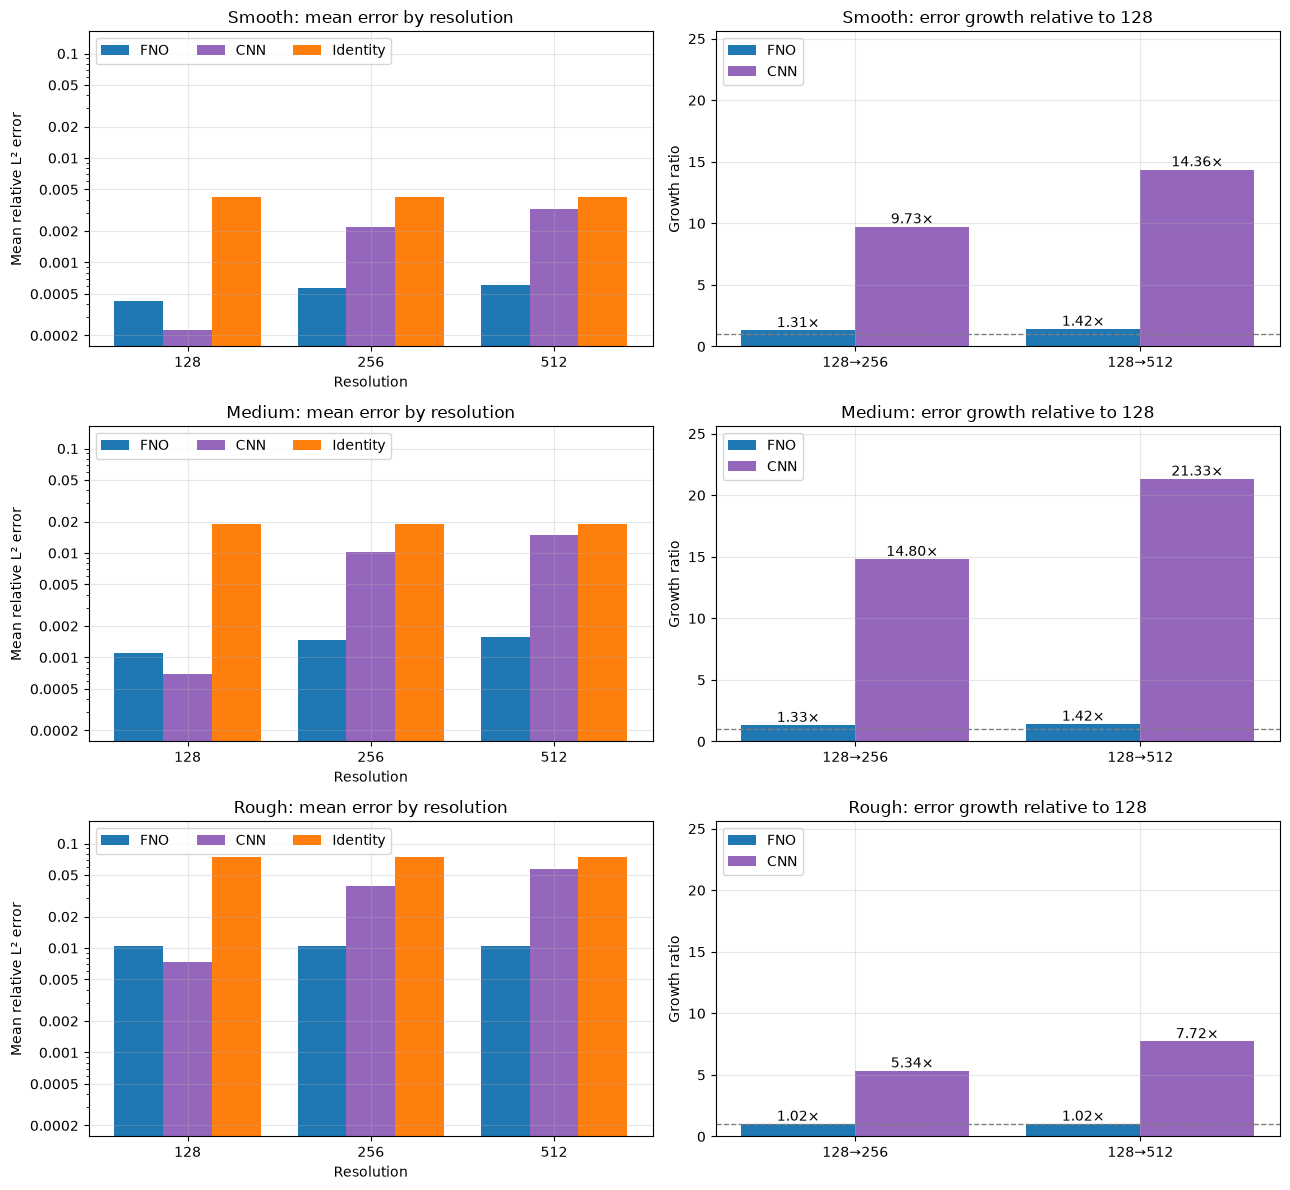

Saved fno_vs_cnn_buckets.png


In [12]:
fig, axes = plt.subplots(len(BUCKETS), 2, figsize=(13, 4 * len(BUCKETS)), sharey='col')
x = np.arange(len(RESOLUTIONS))
all_errors, all_growth = [], []

for row, b in enumerate(BUCKETS):
    name = b.capitalize()

    # Left: mean error of each model and the identity baseline at each resolution
    ax = axes[row, 0]
    series = [(m, means(m, b), MODEL_COLORS[m]) for m in MODELS] + [('Identity', identity_means(b), 'C1')]
    w = 0.8 / len(series)
    for k, (label, values, color) in enumerate(series):
        ax.bar(x + (k - (len(series) - 1) / 2) * w, values, w, label=label, color=color)
        all_errors += values
    ax.set_xticks(x)
    ax.set_xticklabels([str(res) for res in RESOLUTIONS])
    ax.set_xlabel('Resolution')
    ax.set_ylabel('Mean relative L² error')
    ax.set_yscale('log')
    ax.set_title(f'{name}: mean error by resolution')
    ax.legend(loc='upper left', ncol=len(series))
    ax.grid(True, alpha=0.3)

    # Right: how much each model's error grows when moving off the training resolution
    ax = axes[row, 1]
    gx = np.arange(2)
    gw = 0.8 / len(MODELS)
    for k, m in enumerate(MODELS):
        g = growth(m, b)
        all_growth += g
        pos = gx + (k - (len(MODELS) - 1) / 2) * gw
        ax.bar(pos, g, gw, label=m, color=MODEL_COLORS[m])
        for p, value in zip(pos, g):
            ax.text(p, value, f'{value:.2f}×', ha='center', va='bottom')
    ax.axhline(1.0, color='gray', linestyle='--', linewidth=1)
    ax.set_xticks(gx)
    ax.set_xticklabels(['128→256', '128→512'])
    ax.set_ylabel('Growth ratio')
    ax.set_title(f'{name}: error growth relative to 128')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)

readable_log_axis(axes[0, 0], all_errors)
axes[0, 1].set_ylim(0, max(all_growth) * 1.2)

plt.tight_layout()
plt.savefig('fno_vs_cnn_buckets.png', dpi=150)
plt.show()
print("Saved fno_vs_cnn_buckets.png")